In [1]:
import requests
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from bs4 import BeautifulSoup
from datetime import datetime

sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

RAW_DIR = Path("../datos/raw")
INTERIM_DIR = Path("../datos/interim")
EXTERNOS_DIR = Path("../datos/externos")
CLEAN_DIR = Path("../datos/clean")

for d in [RAW_DIR, INTERIM_DIR, EXTERNOS_DIR, CLEAN_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(" Entorno de O1 Meteorología listo")

 Entorno de O1 Meteorología listo


In [2]:

LAT_CORUNA = 43.3623
LON_CORUNA = -8.4115

carreras_info = [
    {
        "id_carrera": "carrera_01",
        "evento_id": "3210",
        "nombre_carrera": "Torre de Hércules",
        "barrio": "Torre de Hércules",
        "fecha": "2026-03-14",
        "hora_salida": "17:00",
        "latitud": LAT_CORUNA,
        "longitud": LON_CORUNA
    },
    {
        "id_carrera": "carrera_02",
        "evento_id": "3211",
        "nombre_carrera": "Matogrande-Xuxán",
        "barrio": "Matogrande - Xuxán",
        "fecha": "2026-04-12",
        "hora_salida": "10:00",
        "latitud": LAT_CORUNA,
        "longitud": LON_CORUNA
    },
    {
        "id_carrera": "carrera_03",
        "evento_id": "3212",
        "nombre_carrera": "San Pedro de Visma",
        "barrio": "San Pedro de Visma",
        "fecha": "2026-05-10",
        "hora_salida": "10:00",
        "latitud": LAT_CORUNA,
        "longitud": LON_CORUNA
    },
    {
        "id_carrera": "carrera_04",
        "evento_id": "3213",
        "nombre_carrera": "Os Rosales",
        "barrio": "Os Rosales",
        "fecha": "2026-05-31",
        "hora_salida": "10:00",
        "latitud": LAT_CORUNA,
        "longitud": LON_CORUNA
    },
    {
        "id_carrera": "carrera_05",
        "evento_id": "3214",
        "nombre_carrera": "Volta a Oza",
        "barrio": "Oza - Castrillón",
        "fecha": "2026-09-13",
        "hora_salida": "10:00",
        "latitud": LAT_CORUNA,
        "longitud": LON_CORUNA
    },
    {
        "id_carrera": "carrera_06",
        "evento_id": "3215",
        "nombre_carrera": "Ventorrillo",
        "barrio": "Ventorrillo",
        "fecha": "2026-10-25",
        "hora_salida": "10:00",
        "latitud": LAT_CORUNA,
        "longitud": LON_CORUNA
    }
]

df_carreras = pd.DataFrame(carreras_info)
print("=== CALENDARIO OFICIAL Y LOCALIZACIÓN DE CARRERAS ===")
display(df_carreras[["id_carrera", "nombre_carrera", "fecha", "hora_salida", "barrio"]])

=== CALENDARIO OFICIAL Y LOCALIZACIÓN DE CARRERAS ===


,id_carrera,nombre_carrera,fecha,hora_salida,barrio
0,carrera_01,Torre de Hércules,2026-03-14,17:00,Torre de Hércules
1,carrera_02,Matogrande-Xuxán,2026-04-12,10:00,Matogrande - Xuxán
2,carrera_03,San Pedro de Visma,2026-05-10,10:00,San Pedro de Visma
3,carrera_04,Os Rosales,2026-05-31,10:00,Os Rosales
4,carrera_05,Volta a Oza,2026-09-13,10:00,Oza - Castrillón
5,carrera_06,Ventorrillo,2026-10-25,10:00,Ventorrillo


In [3]:


datos_meteorologicos = []
timestamp_consulta = datetime.now().isoformat()

print("Consultando API meteorológica para cada fecha de carrera...\n")

for row in carreras_info:
    fecha = row["fecha"]
    id_c = row["id_carrera"]
    
    url_api = "https://archive-api.open-meteo.com/v1/archive"
    params = {
        "latitude": row["latitud"],
        "longitude": row["longitud"],
        "start_date": fecha,
        "end_date": fecha,
        "daily": [
            "temperature_2m_max",
            "temperature_2m_min",
            "temperature_2m_mean",
            "precipitation_sum",
            "wind_speed_10m_max"
        ],
        "timezone": "Europe/Madrid"
    }
    
    try:
        resp = requests.get(url_api, params=params, timeout=10)
        resp.raise_for_status()
        data = resp.json()["daily"]
        
        registro_meteo = {
            "id_carrera": id_c,
            "fecha": fecha,
            "temp_media_c": data["temperature_2m_mean"][0],
            "temp_max_c": data["temperature_2m_max"][0],
            "temp_min_c": data["temperature_2m_min"][0],
            "precipitacion_mm": data["precipitation_sum"][0],
            "viento_max_kmh": data["wind_speed_10m_max"][0],
            "hubo_lluvia": data["precipitation_sum"][0] > 0.5,
            "fuente_meteo": "Open-Meteo Historical Archive API (ERA5)",
            "estacion_referencia": "A Coruña (43.3623 N, -8.4115 W)",
            "fecha_consulta_api": timestamp_consulta
        }
        datos_meteorologicos.append(registro_meteo)
        print(f"   {id_c} ({fecha}): Temp Media = {registro_meteo['temp_media_c']}°C | Lluvia = {registro_meteo['precipitacion_mm']} mm")
        
    except Exception as e:
        print(f"   Error consultando {id_c}: {e}")

df_meteo = pd.DataFrame(datos_meteorologicos)

archivo_meteo = EXTERNOS_DIR / "meteorologia_corunacorre.csv"
df_meteo.to_csv(archivo_meteo, index=False)
print(f"\n Datos meteorológicos guardados en: {archivo_meteo}")

Consultando API meteorológica para cada fecha de carrera...

   carrera_01 (2026-03-14): Temp Media = 10.7°C | Lluvia = 8.3 mm
   carrera_02 (2026-04-12): Temp Media = 9.5°C | Lluvia = 2.3 mm
   carrera_03 (2026-05-10): Temp Media = 13.3°C | Lluvia = 14.7 mm
   carrera_04 (2026-05-31): Temp Media = 17.2°C | Lluvia = 0.0 mm
   carrera_05 (2026-09-13): Temp Media = 22.4°C | Lluvia = 0.0 mm
   carrera_06 (2026-10-25): Temp Media = 17.2°C | Lluvia = 0.6 mm

 Datos meteorológicos guardados en: ../datos/externos/meteorologia_corunacorre.csv


In [4]:

df_reg = pd.read_csv(INTERIM_DIR / "registro_extraccion.csv")

df_carreiras = pd.merge(df_carreras, df_reg[["id_carrera", "total_participantes"]], on="id_carrera", how="left")
df_carreiras = pd.merge(df_carreiras, df_meteo, on=["id_carrera", "fecha"], how="left")

assert df_carreiras["id_carrera"].nunique() == len(df_carreiras), "¡Error! Clave id_carrera duplicada en carreiras.csv"

archivo_carreiras_base = INTERIM_DIR / "carreiras_base.csv"
df_carreiras.to_csv(archivo_carreiras_base, index=False)
print(f"Calendario base guardado en: {archivo_carreiras_base}")

display(df_carreiras[["id_carrera", "nombre_carrera", "fecha", "total_participantes", "temp_media_c", "precipitacion_mm", "hubo_lluvia"]])

Calendario base guardado en: ../datos/interim/carreiras_base.csv


,id_carrera,nombre_carrera,fecha,total_participantes,temp_media_c,precipitacion_mm,hubo_lluvia
0,carrera_01,Torre de Hércules,2026-03-14,1489,10.7,8.3,True
1,carrera_02,Matogrande-Xuxán,2026-04-12,929,9.5,2.3,True
2,carrera_03,San Pedro de Visma,2026-05-10,795,13.3,14.7,True
3,carrera_04,Os Rosales,2026-05-31,875,17.2,0.0,False
4,carrera_05,Volta a Oza,2026-09-13,659,22.4,0.0,False
5,carrera_06,Ventorrillo,2026-10-25,643,17.2,0.6,True


/tmp/ipykernel_579318/221273443.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


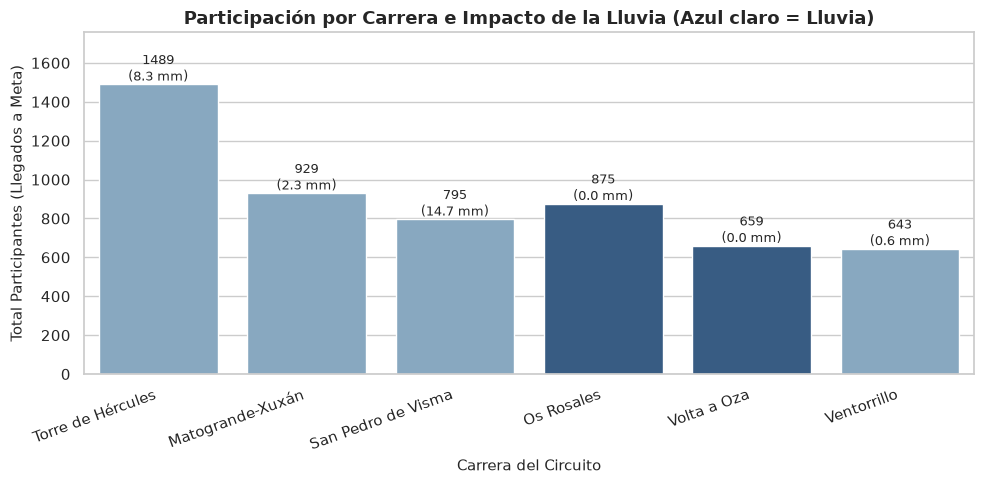


 INTERPRETACIÓN Y LIMITACIONES METODOLÓGICAS:
1. Observación: La carrera con mayor lluvia registrada (San Pedro de Visma, 14.7 mm) tuvo 795 participantes,
   mientras que carreras posteriores sin lluvia (Volta a Oza o Ventorrillo) tuvieron menor participación (659 y 643).
2. Advertencia obligatoria (Paso 20 de la guía): Al disponer únicamente de 6 carreras (N=6),
   una correlación o diferencia estadística NO demuestra relación causal. Factores como el desgaste del calendario,
   la fecha del año (vacaciones o fiestas locales) o el desnivel del circuito pueden ser más determinantes que el clima.


In [5]:

plt.figure(figsize=(10, 5))
colores = ['#2b5c8f' if not row['hubo_lluvia'] else '#7fa9c9' for _, row in df_carreiras.iterrows()]

ax = sns.barplot(
    data=df_carreiras,
    x="nombre_carrera",
    y="total_participantes",
    palette=colores
)

plt.title("Participación por Carrera e Impacto de la Lluvia (Azul claro = Lluvia)", fontsize=13, fontweight='bold')
plt.xlabel("Carrera del Circuito", fontsize=11)
plt.ylabel("Total Participantes (Llegados a Meta)", fontsize=11)
plt.xticks(rotation=20, ha='right')

for idx, row in df_carreiras.iterrows():
    texto_barra = f"{row['total_participantes']}\n({row['precipitacion_mm']} mm)"
    ax.text(idx, row['total_participantes'] + 20, texto_barra, ha='center', fontsize=9)

plt.ylim(0, max(df_carreiras['total_participantes']) * 1.18)
plt.tight_layout()
plt.savefig("../output/participacion_vs_lluvia.png", dpi=150)
plt.show()

print("\n INTERPRETACIÓN Y LIMITACIONES METODOLÓGICAS:")
print("1. Observación: La carrera con mayor lluvia registrada (San Pedro de Visma, 14.7 mm) tuvo 795 participantes,")
print("   mientras que carreras posteriores sin lluvia (Volta a Oza o Ventorrillo) tuvieron menor participación (659 y 643).")
print("2. Advertencia obligatoria (Paso 20 de la guía): Al disponer únicamente de 6 carreras (N=6),")
print("   una correlación o diferencia estadística NO demuestra relación causal. Factores como el desgaste del calendario,")
print("   la fecha del año (vacaciones o fiestas locales) o el desnivel del circuito pueden ser más determinantes que el clima.")

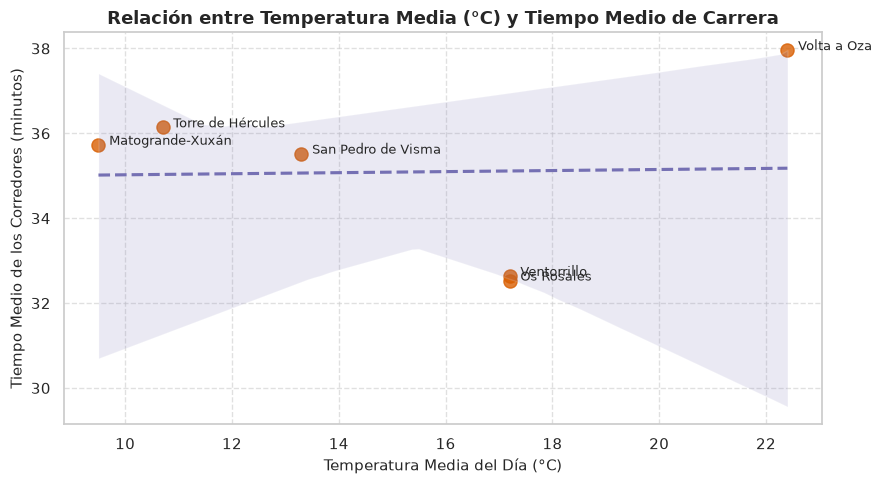


 INTERPRETACIÓN:
- Los diferentes recorridos tienen distancias y perfiles altimétricos distintos (ej. cuestas en Ventorrillo vs llano en Torre).
- Por tanto, las variaciones de tiempo responden principalmente al trazado de la prueba y no a la temperatura.
- Se concluye una relación meramente descriptiva, no causal.


In [6]:

tiempos_medios = []

for id_c in df_carreiras["id_carrera"]:
    df_i = pd.read_csv(INTERIM_DIR / f"{id_c}_interim.csv")
    
    def tiempo_a_segundos(t_str):
        try:
            partes = str(t_str).split(":")
            if len(partes) == 3:
                return int(partes[0]) * 3600 + int(partes[1]) * 60 + int(partes[2])
            elif len(partes) == 2:
                return int(partes[0]) * 60 + int(partes[1])
            return None
        except:
            return None

    segundos = df_i["tiempo_oficial"].apply(tiempo_a_segundos).dropna()
    tiempo_medio_min = (segundos.mean() / 60) if len(segundos) > 0 else None
    
    tiempos_medios.append({
        "id_carrera": id_c,
        "tiempo_medio_min": round(tiempo_medio_min, 2)
    })

df_tiempos = pd.DataFrame(tiempos_medios)
df_analisis_clima = pd.merge(df_carreiras, df_tiempos, on="id_carrera")

plt.figure(figsize=(9, 5))
sns.regplot(
    data=df_analisis_clima,
    x="temp_media_c",
    y="tiempo_medio_min",
    scatter_kws={"s": 90, "color": "#d95f02"},
    line_kws={"color": "#7570b3", "linestyle": "--"}
)

for _, r in df_analisis_clima.iterrows():
    plt.text(r['temp_media_c'] + 0.2, r['tiempo_medio_min'], r['nombre_carrera'], fontsize=9)

plt.title("Relación entre Temperatura Media (°C) y Tiempo Medio de Carrera", fontsize=13, fontweight='bold')
plt.xlabel("Temperatura Media del Día (°C)", fontsize=11)
plt.ylabel("Tiempo Medio de los Corredores (minutos)", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("../output/temperatura_vs_tiempos.png", dpi=150)
plt.show()

print("\n INTERPRETACIÓN:")
print("- Los diferentes recorridos tienen distancias y perfiles altimétricos distintos (ej. cuestas en Ventorrillo vs llano en Torre).")
print("- Por tanto, las variaciones de tiempo responden principalmente al trazado de la prueba y no a la temperatura.")
print("- Se concluye una relación meramente descriptiva, no causal.")